In [1]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import os

if "CENSUS_API_KEY" not in os.environ:
    with open("/Users/jessicamoon/Desktop/SI485/.env") as f:
        for line in f:
            if line.startswith("CENSUS_API_KEY="):
                os.environ["CENSUS_API_KEY"] = line.strip().split("=", 1)[1]

API_KEY = os.environ["CENSUS_API_KEY"]
print("API key loaded:", API_KEY is not None)

/Users/jessicamoon/Desktop/SI485/dominos.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


API key loaded: True


In [2]:
YEAR = '2024'
DATASET = 'acs/acs5'
STATE_FIPS = '48'  #Texas

VARIABLES = 'NAME,B19013_001E,B01002_001E'

base_url = f'https://api.census.gov/data/{YEAR}/{DATASET}'

api_url = (
    f'{base_url}?get={VARIABLES}'
    f'&for=county:*'
    f'&in=state:{STATE_FIPS}'
    f'&key={API_KEY}'
)

In [3]:
response = requests.get(api_url, timeout=30)
response.raise_for_status()

data = response.json()

df = pd.DataFrame(data[1:], columns=data[0])

# Rename columns
df = df.rename(columns={
    'B19013_001E': 'Median_Income',
    'B01002_001E': 'Median_Age'
})

# Convert to numeric
df['Median_Income'] = pd.to_numeric(df['Median_Income'], errors='coerce')
df['Median_Age'] = pd.to_numeric(df['Median_Age'], errors='coerce')

# Handle missing values
df.loc[df['Median_Income'] < 0, 'Median_Income'] = float('nan')
df.loc[df['Median_Age'] < 0, 'Median_Age'] = float('nan')

# Create county identifier
df['GEOID'] = df['state'] + df['county']

df.head()

,NAME,Median_Income,Median_Age,state,county,GEOID
0,"Anderson County, Texas",62068.0,39.7,48,001,48001
1,"Andrews County, Texas",72242.0,33.0,48,003,48003
2,"Angelina County, Texas",60960.0,37.8,48,005,48005
3,"Aransas County, Texas",69466.0,49.9,48,007,48007
4,"Archer County, Texas",72159.0,42.8,48,009,48009


In [4]:
shapefile_url = (
    "https://www2.census.gov/geo/tiger/GENZ2022/shp/"
    "cb_2022_us_county_20m.zip"
)

counties_gdf = gpd.read_file(shapefile_url)

# Keep only Texas
tx_counties = counties_gdf[
    counties_gdf['STATEFP'] == STATE_FIPS
].copy()

tx_counties.head()

,STATEFP,COUNTYFP,COUNTYNS,AFFGEOID,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
20,48,273,01383922,0500000US48273,48273,Kleberg,Kleberg County,TX,Texas,06,2282572444,541041659,"POLYGON ((-98.05946 27.63586, -97.94215 27.635..."
26,48,011,01383791,0500000US48011,48011,Armstrong,Armstrong County,TX,Texas,06,2354617585,12183672,"POLYGON ((-101.62294 35.18312, -101.08628 35.1..."
32,48,171,01383871,0500000US48171,48171,Gillespie,Gillespie County,TX,Texas,06,2740731307,9000601,"POLYGON ((-99.304 30.49983, -98.96423 30.49848..."
45,48,209,01383890,0500000US48209,48209,Hays,Hays County,TX,Texas,06,1753038966,5043724,"POLYGON ((-98.17298 30.35631, -98.01083 30.240..."
49,48,369,01383970,0500000US48369,48369,Parmer,Parmer County,TX,Texas,06,2281317978,11355762,"POLYGON ((-103.04395 34.37956, -103.04307 34.6..."


In [5]:
merged_gdf = tx_counties.merge(
    df,
    on='GEOID',
    how='left'
)

print("Number of counties:", len(merged_gdf))

merged_gdf.head()

Number of counties: 254


,STATEFP,COUNTYFP,COUNTYNS,AFFGEOID,GEOID,NAME_x,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry,NAME_y,Median_Income,Median_Age,state,county
0,48,273,01383922,0500000US48273,48273,Kleberg,Kleberg County,TX,Texas,06,2282572444,541041659,"POLYGON ((-98.05946 27.63586, -97.94215 27.635...","Kleberg County, Texas",61292.0,29.0,48,273
1,48,011,01383791,0500000US48011,48011,Armstrong,Armstrong County,TX,Texas,06,2354617585,12183672,"POLYGON ((-101.62294 35.18312, -101.08628 35.1...","Armstrong County, Texas",72750.0,43.6,48,011
2,48,171,01383871,0500000US48171,48171,Gillespie,Gillespie County,TX,Texas,06,2740731307,9000601,"POLYGON ((-99.304 30.49983, -98.96423 30.49848...","Gillespie County, Texas",76162.0,50.7,48,171
3,48,209,01383890,0500000US48209,48209,Hays,Hays County,TX,Texas,06,1753038966,5043724,"POLYGON ((-98.17298 30.35631, -98.01083 30.240...","Hays County, Texas",89097.0,34.1,48,209
4,48,369,01383970,0500000US48369,48369,Parmer,Parmer County,TX,Texas,06,2281317978,11355762,"POLYGON ((-103.04395 34.37956, -103.04307 34.6...","Parmer County, Texas",69735.0,36.3,48,369


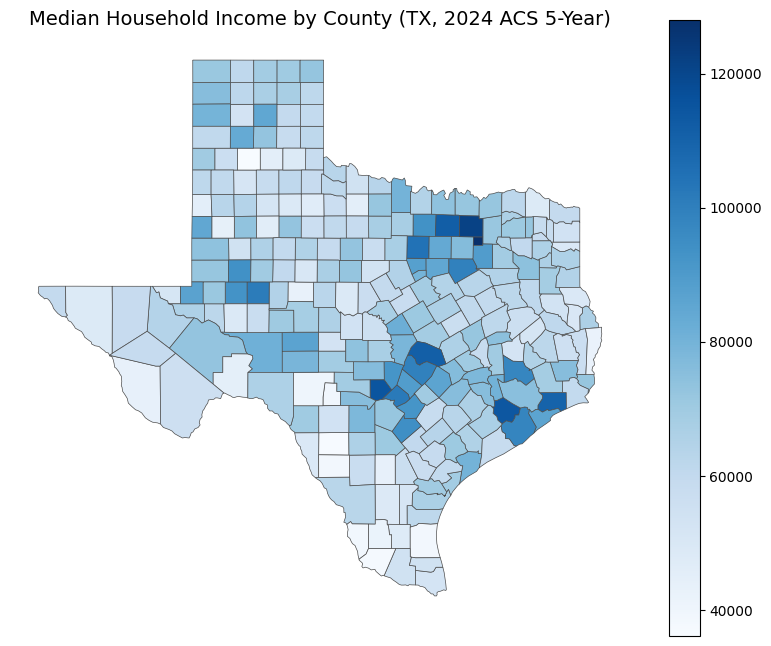

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))

merged_gdf.plot(
    column='Median_Income',
    cmap='Blues',
    linewidth=0.5,
    edgecolor='0.3',
    legend=True,
    missing_kwds={'color': 'lightgrey'},
    ax=ax
)

ax.set_title('Median Household Income by County (TX, 2024 ACS 5-Year)', fontsize=14)
ax.axis('off')

plt.show()

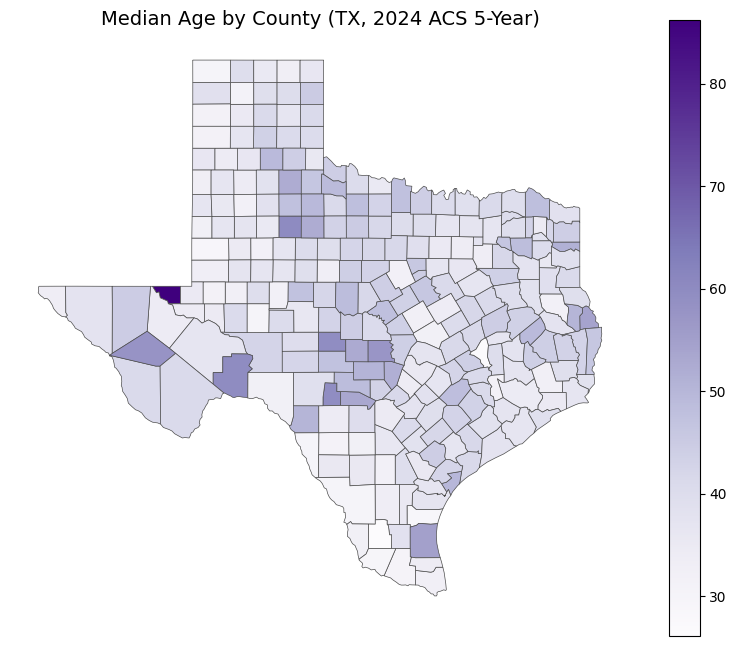

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))

merged_gdf.plot(
    column='Median_Age',
    cmap='Purples',
    linewidth=0.5,
    edgecolor='0.3',
    legend=True,
    missing_kwds={'color': 'lightgrey'},
    ax=ax
)

ax.set_title('Median Age by County (TX, 2024 ACS 5-Year)', fontsize=14)
ax.axis('off')

plt.show()

In [8]:
summary_df = df.copy()

summary_df['NAME'] = summary_df['NAME'].str.replace(', Michigan', '', regex=False)

print("Highest median income:")
print(summary_df.nlargest(5, 'Median_Income')[['NAME', 'Median_Income']].to_string(index=False))

print("\nLowest median income:")
print(summary_df.nsmallest(5, 'Median_Income')[['NAME', 'Median_Income']].to_string(index=False))

print("\nOldest median age:")
print(summary_df.nlargest(5, 'Median_Age')[['NAME', 'Median_Age']].to_string(index=False))

print("\nYoungest median age:")
print(summary_df.nsmallest(5, 'Median_Age')[['NAME', 'Median_Age']].to_string(index=False))

Highest median income:
                   NAME  Median_Income
 Rockwall County, Texas       127981.0
   Collin County, Texas       121600.0
  Kendall County, Texas       114962.0
Fort Bend County, Texas       114041.0
   Denton County, Texas       111498.0

Lowest median income:
                 NAME  Median_Income
Swisher County, Texas        36165.0
 Zavala County, Texas        36749.0
  Starr County, Texas        37639.0
 Dimmit County, Texas        38808.0
 Kenedy County, Texas        38882.0

Oldest median age:
                 NAME  Median_Age
 Loving County, Texas        86.2
   Kent County, Texas        60.0
Terrell County, Texas        59.9
 Menard County, Texas        59.5
   Real County, Texas        59.5

Youngest median age:
                  NAME  Median_Age
Jim Hogg County, Texas        26.1
  Brazos County, Texas        26.8
 Kleberg County, Texas        29.0
  Gaines County, Texas        29.3
   Starr County, Texas        29.4
